# Analisis Hasil Eksperimen

## Evaluasi Pengaruh Fitur URL-Only dan Validasi Berbasis Domain terhadap Deteksi Phishing Menggunakan Machine Learning

Notebook ini bertujuan menganalisis hasil eksperimen menggunakan Logistic Regression dan Random Forest pada empat skenario:

- A: Full Features + Random Split
- B: URL-Only + Random Split
- C: URL-Only + Domain-Grouped Split
- D: Full Features + Domain-Grouped Split

Analisis meliputi performa klasifikasi, perubahan F1-score, waktu komputasi, dan kesalahan prediksi.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

sns.set_theme(style="whitegrid")

RESULTS_DIR = Path("../results")
FIGURES_DIR = Path("../figures")

FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print("Library berhasil diimpor.")

Library berhasil diimpor.


In [2]:
results_df = pd.read_csv(
    RESULTS_DIR / "all_scenario_metrics.csv"
)

print("Jumlah hasil eksperimen:", len(results_df))

display(results_df.head())

Jumlah hasil eksperimen: 8


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,Training Time (s),Inference Time (s),Inference per Sample (ms),TN,FP,FN,TP,Scenario,Feature Type,Validation,Number of Features,Training Samples,Testing Samples,Random State
0,Logistic Regression,0.999278,0.999768,0.998541,0.999154,0.999964,0.390694,0.022785,0.000323,40448,7,44,30112,A,Full Features,Random Split,47,164759,70611,42
1,Random Forest,0.999830,0.999867,0.999735,0.999801,0.999998,4.184473,0.084865,0.001202,40451,4,8,30148,A,Full Features,Random Split,47,164759,70611,42
2,Logistic Regression,0.996120,0.999465,0.991444,0.995439,0.998426,0.518177,0.013684,0.000194,40439,16,258,29898,B,URL-Only,Random Split,19,164759,70611,42
3,Random Forest,0.997465,0.999334,0.994727,0.997025,0.998226,3.346972,0.120061,0.001700,40435,20,159,29997,B,URL-Only,Random Split,19,164759,70611,42
4,Logistic Regression,0.996312,0.999628,0.991677,0.995637,0.998484,0.371176,0.013901,0.000198,40413,11,248,29549,C,URL-Only,Domain-Grouped Split,19,165149,70221,42


In [3]:
required_columns = [
    "Scenario",
    "Model",
    "Feature Type",
    "Validation",
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score",
    "ROC-AUC",
    "Training Time (s)",
    "Inference Time (s)",
    "Inference per Sample (ms)",
    "TN",
    "FP",
    "FN",
    "TP"
]

assert all(
    col in results_df.columns
    for col in required_columns
), "Terdapat kolom yang tidak ditemukan."

assert len(results_df) == 8, \
    "Jumlah konfigurasi eksperimen tidak sesuai."

assert set(results_df["Scenario"]) == {
    "A", "B", "C", "D"
}, "Skenario tidak lengkap."

assert not results_df[required_columns].isna().any().any(), \
    "Terdapat missing values."

assert all(
    results_df.groupby("Scenario")["Model"].nunique() == 2
), "Setiap skenario harus memiliki dua model."

print("Validasi hasil eksperimen berhasil.")

Validasi hasil eksperimen berhasil.


In [4]:
performance_table = results_df[
    [
        "Scenario",
        "Model",
        "Feature Type",
        "Validation",
        "Number of Features",
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "ROC-AUC"
    ]
].copy()

display(performance_table.round(6))

,Scenario,Model,Feature Type,Validation,Number of Features,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,A,Logistic Regression,Full Features,Random Split,47,0.999278,0.999768,0.998541,0.999154,0.999964
1,A,Random Forest,Full Features,Random Split,47,0.999830,0.999867,0.999735,0.999801,0.999998
2,B,Logistic Regression,URL-Only,Random Split,19,0.996120,0.999465,0.991444,0.995439,0.998426
3,B,Random Forest,URL-Only,Random Split,19,0.997465,0.999334,0.994727,0.997025,0.998226
4,C,Logistic Regression,URL-Only,Domain-Grouped Split,19,0.996312,0.999628,0.991677,0.995637,0.998484
5,C,Random Forest,URL-Only,Domain-Grouped Split,19,0.997465,0.998687,0.995335,0.997008,0.998490
6,D,Logistic Regression,Full Features,Domain-Grouped Split,47,0.999231,0.999530,0.998658,0.999093,0.999980
7,D,Random Forest,Full Features,Domain-Grouped Split,47,0.999858,0.999966,0.999698,0.999832,0.999999


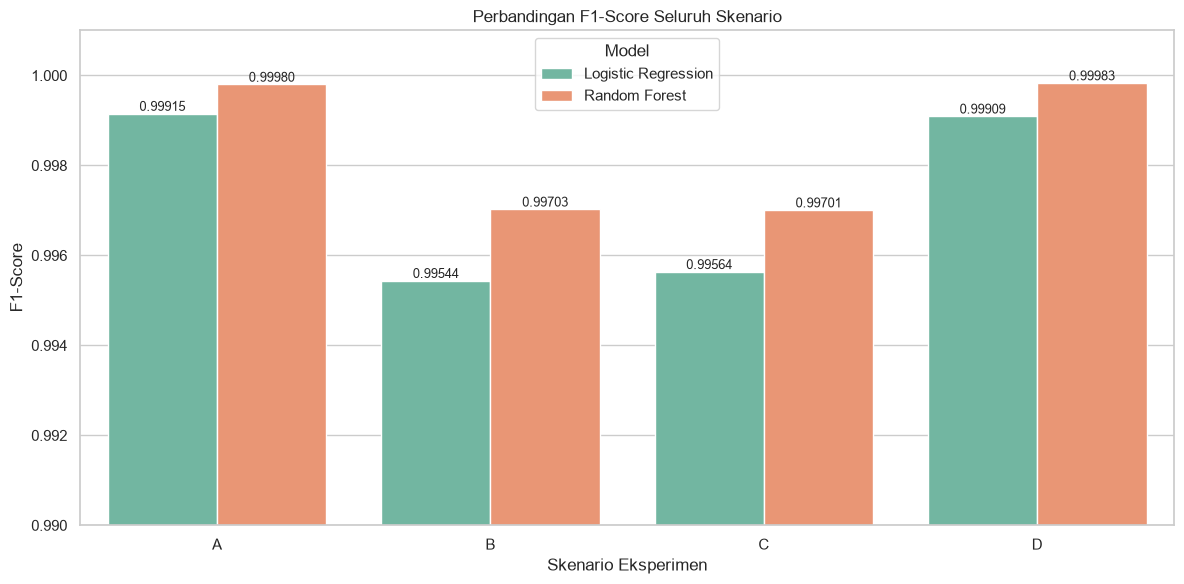

In [5]:
plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=results_df,
    x="Scenario",
    y="F1-Score",
    hue="Model",
    palette="Set2"
)

plt.title("Perbandingan F1-Score Seluruh Skenario")
plt.xlabel("Skenario Eksperimen")
plt.ylabel("F1-Score")

plt.ylim(0.99, 1.001)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.5f",
        fontsize=9
    )

plt.legend(title="Model")
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "experiment_f1_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

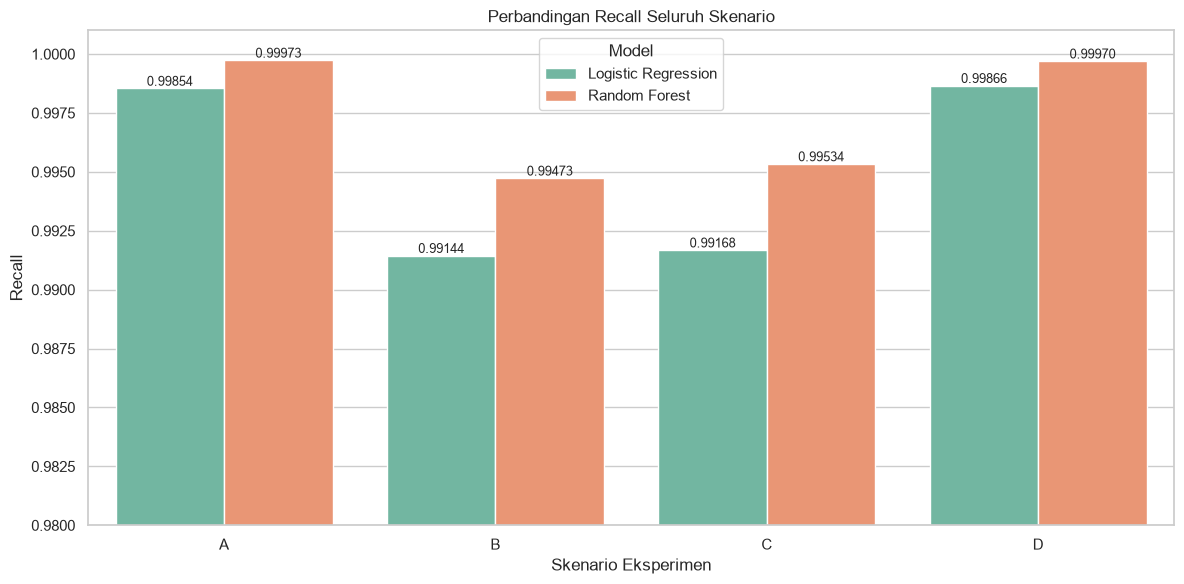

In [6]:
plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=results_df,
    x="Scenario",
    y="Recall",
    hue="Model",
    palette="Set2"
)

plt.title("Perbandingan Recall Seluruh Skenario")
plt.xlabel("Skenario Eksperimen")
plt.ylabel("Recall")

plt.ylim(0.98, 1.001)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.5f",
        fontsize=9
    )

plt.legend(title="Model")
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "experiment_recall_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

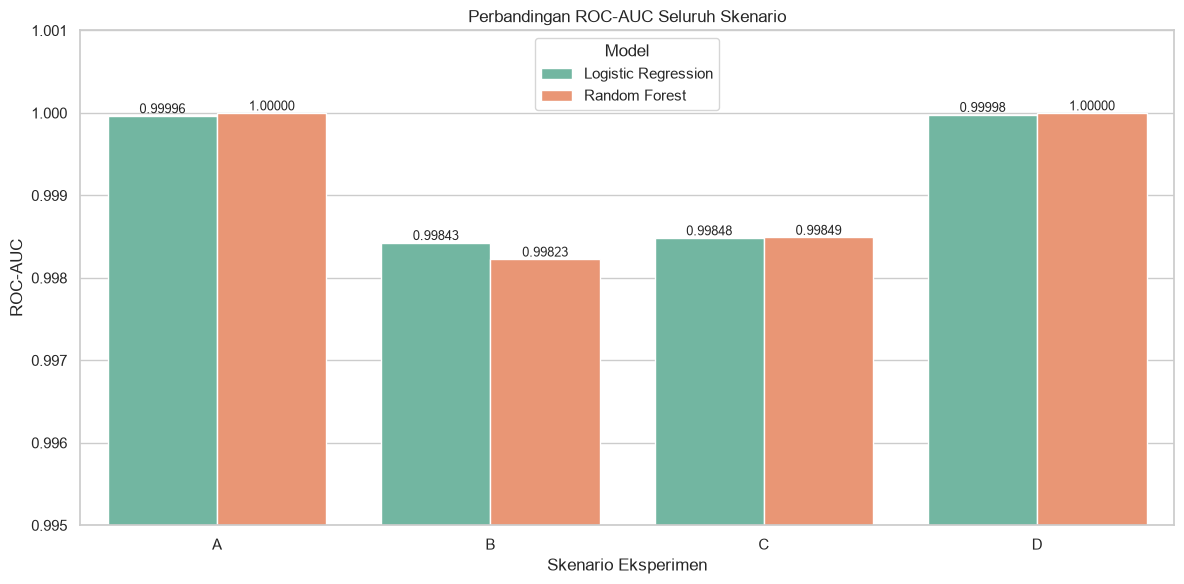

In [7]:
plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=results_df,
    x="Scenario",
    y="ROC-AUC",
    hue="Model",
    palette="Set2"
)

plt.title("Perbandingan ROC-AUC Seluruh Skenario")
plt.xlabel("Skenario Eksperimen")
plt.ylabel("ROC-AUC")

plt.ylim(0.995, 1.001)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.5f",
        fontsize=9
    )

plt.legend(title="Model")
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "experiment_roc_auc_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [8]:
feature_comparison = []

for model in results_df["Model"].unique():

    model_df = results_df[
        results_df["Model"] == model
    ].set_index("Scenario")

    for full_scenario, url_scenario, split_name in [
        ("A", "B", "Random Split"),
        ("D", "C", "Domain-Grouped Split")
    ]:

        full_f1 = model_df.loc[
            full_scenario, "F1-Score"
        ]

        url_f1 = model_df.loc[
            url_scenario, "F1-Score"
        ]

        feature_comparison.append({
            "Model": model,
            "Split": split_name,
            "Full Features F1": full_f1,
            "URL-Only F1": url_f1,
            "F1 Difference (pp)": (
                url_f1 - full_f1
            ) * 100
        })

feature_comparison_df = pd.DataFrame(
    feature_comparison
)

display(feature_comparison_df.round(6))

,Model,Split,Full Features F1,URL-Only F1,F1 Difference (pp)
0,Logistic Regression,Random Split,0.999154,0.995439,-0.371522
1,Logistic Regression,Domain-Grouped Split,0.999093,0.995637,-0.345690
2,Random Forest,Random Split,0.999801,0.997025,-0.277578
3,Random Forest,Domain-Grouped Split,0.999832,0.997008,-0.282407


pp = poin persentase.

Temuan utama: Pembatasan fitur menjadi URL-only menyebabkan penurunan F1-score pada kedua algoritma, baik menggunakan random split maupun domain-grouped split.

Namun, penurunannya relatif kecil, yaitu sekitar 0,28–0,37 poin persentase.

Ini menunjukkan bahwa 19 fitur URL-only masih mampu menghasilkan performa klasifikasi yang tinggi dibandingkan penggunaan 47 fitur lengkap.

Kita perlu berhati-hati dalam menginterpretasikan temuan ini. Hasil tersebut berlaku pada dataset PhiUSIIL dan konfigurasi eksperimen yang digunakan. Belum tentu hasilnya sama pada dataset phishing lain.

In [9]:
split_effect = []

for model in results_df["Model"].unique():

    model_df = results_df[
        results_df["Model"] == model
    ].set_index("Scenario")

    for random_scenario, grouped_scenario, feature_name in [
        ("A", "D", "Full Features"),
        ("B", "C", "URL-Only")
    ]:

        random_f1 = model_df.loc[
            random_scenario, "F1-Score"
        ]

        grouped_f1 = model_df.loc[
            grouped_scenario, "F1-Score"
        ]

        split_effect.append({
            "Model": model,
            "Features": feature_name,
            "Random F1": random_f1,
            "Grouped F1": grouped_f1,
            "F1 Difference (pp)": (
                grouped_f1 - random_f1
            ) * 100
        })

split_effect_df = pd.DataFrame(
    split_effect
)

display(split_effect_df.round(6))

,Model,Features,Random F1,Grouped F1,F1 Difference (pp)
0,Logistic Regression,Full Features,0.999154,0.999093,-0.006041
1,Logistic Regression,URL-Only,0.995439,0.995637,0.019792
2,Random Forest,Full Features,0.999801,0.999832,0.003115
3,Random Forest,URL-Only,0.997025,0.997008,-0.001714


Temuan utama: Perubahan strategi pembagian data dari random split menjadi domain-grouped split menghasilkan perbedaan F1-score yang sangat kecil.

Bahkan, arah perubahannya tidak konsisten.

Pada beberapa konfigurasi, domain-grouped split menghasilkan F1-score sedikit lebih tinggi, sementara pada konfigurasi lainnya sedikit lebih rendah.

Artinya, hipotesis bahwa domain-grouped split selalu menghasilkan performa lebih rendah tidak didukung oleh hasil eksperimen awal kita.

Namun, kita juga belum bisa menyimpulkan bahwa kedua strategi memiliki performa setara karena baru menggunakan satu pembagian data.

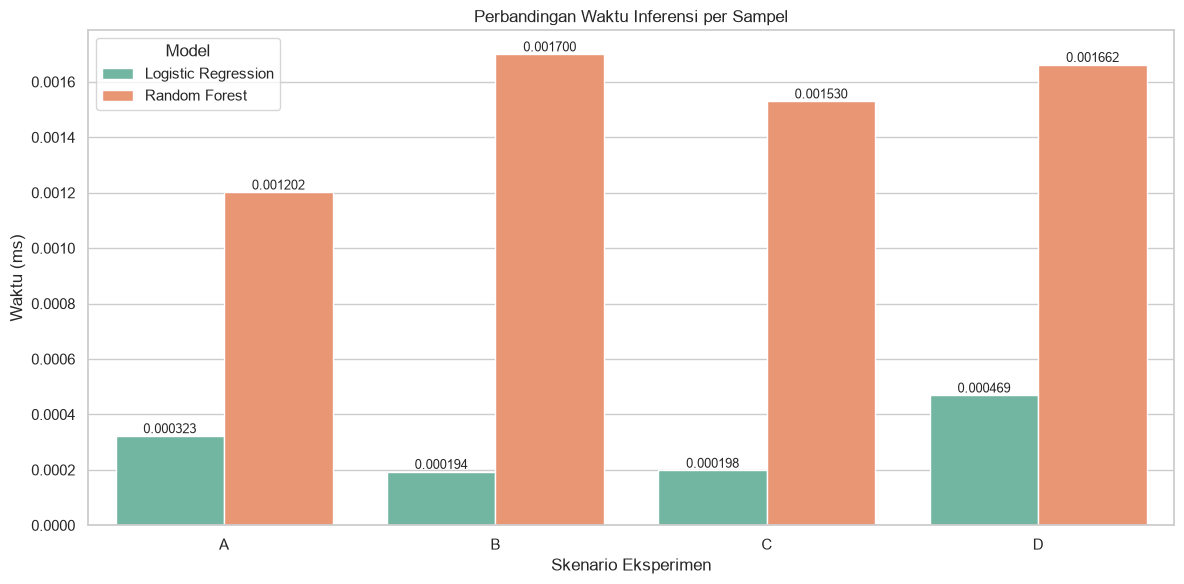

In [10]:
plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=results_df,
    x="Scenario",
    y="Inference per Sample (ms)",
    hue="Model",
    palette="Set2"
)

plt.title("Perbandingan Waktu Inferensi per Sampel")
plt.xlabel("Skenario Eksperimen")
plt.ylabel("Waktu (ms)")

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.6f",
        fontsize=9
    )

plt.legend(title="Model")
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "experiment_inference_time.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

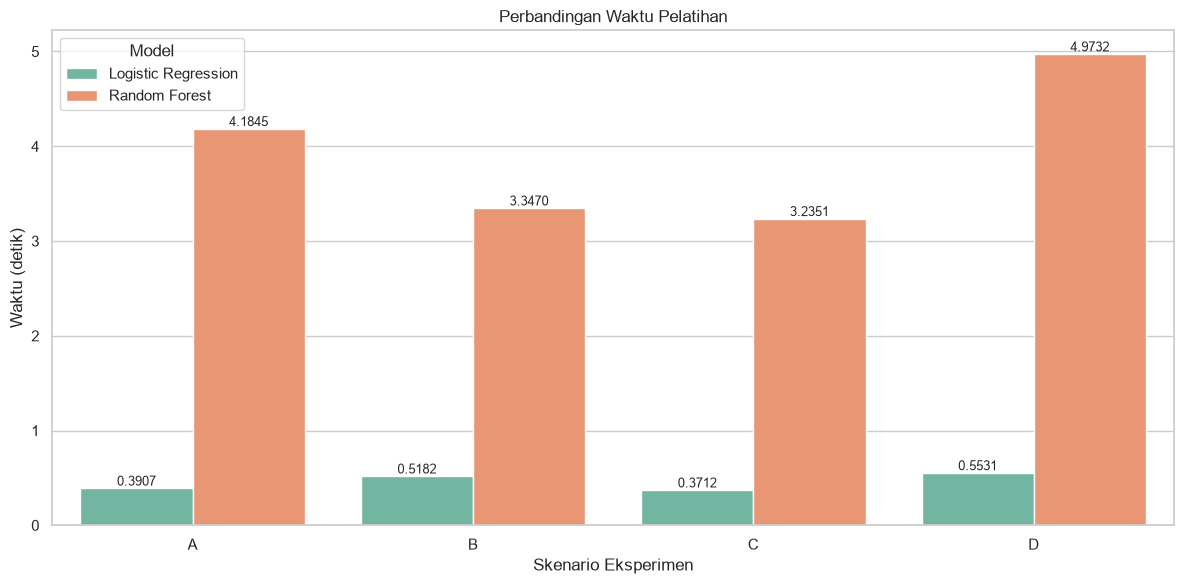

In [11]:
plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=results_df,
    x="Scenario",
    y="Training Time (s)",
    hue="Model",
    palette="Set2"
)

plt.title("Perbandingan Waktu Pelatihan")
plt.xlabel("Skenario Eksperimen")
plt.ylabel("Waktu (detik)")

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.4f",
        fontsize=9
    )

plt.legend(title="Model")
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "experiment_training_time.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [12]:
error_table = results_df[
    [
        "Scenario",
        "Model",
        "TN",
        "FP",
        "FN",
        "TP"
    ]
].copy()

error_table["Total Errors"] = (
    error_table["FP"] +
    error_table["FN"]
)

display(error_table)

,Scenario,Model,TN,FP,FN,TP,Total Errors
0,A,Logistic Regression,40448,7,44,30112,51
1,A,Random Forest,40451,4,8,30148,12
2,B,Logistic Regression,40439,16,258,29898,274
3,B,Random Forest,40435,20,159,29997,179
4,C,Logistic Regression,40413,11,248,29549,259
5,C,Random Forest,40385,39,139,29658,178
6,D,Logistic Regression,40410,14,40,29757,54
7,D,Random Forest,40423,1,9,29788,10


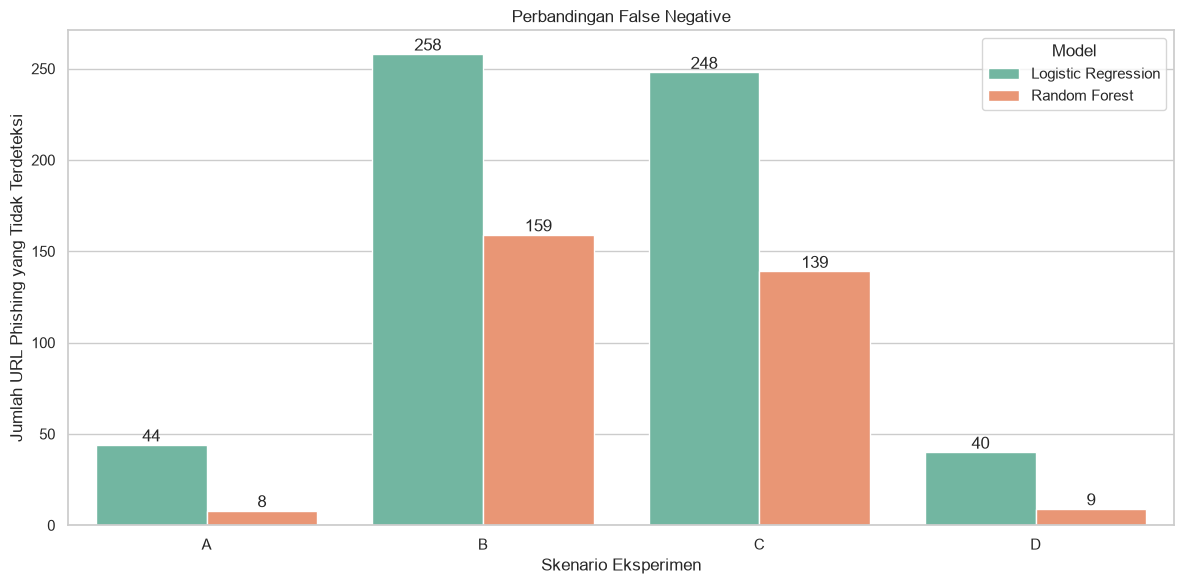

In [13]:
plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=results_df,
    x="Scenario",
    y="FN",
    hue="Model",
    palette="Set2"
)

plt.title("Perbandingan False Negative")
plt.xlabel("Skenario Eksperimen")
plt.ylabel("Jumlah URL Phishing yang Tidak Terdeteksi")

for container in ax.containers:
    ax.bar_label(container)

plt.legend(title="Model")
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "experiment_false_negative.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [14]:
split_comparison = pd.read_csv(
    RESULTS_DIR / "split_comparison.csv"
)

display(split_comparison)

,Split Strategy,Training Samples,Testing Samples,Domain Overlap
0,Random Split,164759,70611,2633
1,Domain-Grouped Split,165149,70221,0


In [15]:
best_result = results_df.loc[
    results_df["F1-Score"].idxmax()
]

print("Model dengan F1-Score tertinggi:")
print("Skenario:", best_result["Scenario"])
print("Model:", best_result["Model"])
print("F1-Score:", best_result["F1-Score"])
print("Accuracy:", best_result["Accuracy"])
print("Recall:", best_result["Recall"])
print("ROC-AUC:", best_result["ROC-AUC"])

Model dengan F1-Score tertinggi:
Skenario: D
Model: Random Forest
F1-Score: 0.9998321753432015
Accuracy: 0.9998575924580966
Recall: 0.9996979561700843
ROC-AUC: 0.9999991315999128


In [16]:
performance_table.to_csv(
    RESULTS_DIR / "experiment_performance_summary.csv",
    index=False
)

feature_comparison_df.to_csv(
    RESULTS_DIR / "feature_comparison.csv",
    index=False
)

split_effect_df.to_csv(
    RESULTS_DIR / "split_effect_comparison.csv",
    index=False
)

error_table.to_csv(
    RESULTS_DIR / "experiment_error_analysis.csv",
    index=False
)

print("Seluruh hasil analisis berhasil disimpan.")

Seluruh hasil analisis berhasil disimpan.


Berdasarkan hasil eksperimen pada dataset PhiUSIIL, Random Forest menghasilkan F1-score lebih tinggi dibandingkan Logistic Regression pada seluruh skenario pengujian. Penggunaan fitur URL-only menurunkan F1-score sekitar 0,28–0,37 poin persentase dibandingkan penggunaan fitur lengkap. Meskipun demikian, kedua algoritma tetap menghasilkan F1-score di atas 99,5% menggunakan fitur URL-only.

Perbandingan strategi random split dan domain-grouped split menunjukkan perubahan F1-score yang relatif kecil dan tidak memiliki arah yang konsisten. Hal ini menunjukkan bahwa dugaan penurunan performa akibat pemisahan domain belum didukung secara konsisten oleh hasil eksperimen awal.

Hasil tersebut masih perlu diperkuat melalui pengujian dengan beberapa random seed dan pemeriksaan lebih lanjut terhadap asal-usul fitur. Oleh karena itu, temuan saat ini diperlakukan sebagai hasil eksperimen awal, bukan bukti bahwa kedua strategi validasi memiliki performa yang setara.